# Comparação entre observações históricas e o modelo HEATLim

Este notebook compara as observações horárias de temperatura do ar e umidade relativa com as 12 combinações do modelo HEATLim: duas exposições, dois perfis e três durações. A temperatura de bulbo úmido medida é usada para validar a consistência psicrométrica das observações.

**Definições:** um limite de sobrevivência é ultrapassado quando `survivable == False`; um limite de habitabilidade é ultrapassado quando não há sobrevivência ou quando `survive_but_not_livable == True`. Também é calculada a fração de horas com `Mmax < 2,3 MET`, valor de referência para atividade leve, incluindo automaticamente as condições não habitáveis.

**Cautela de exposição:** os dados da estação são externos. `Day-Outdoors` é aplicado às 06–17 h; `Night-Indoors` é aplicado às 18–05 h como uma aproximação sem radiação solar. Sem medições internas, este último não representa literalmente a temperatura de uma residência.

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import HEATLim

INICIO = "1995-01-01"
FIM = "2024-12-31 23:00:00"
HORA_INICIO_DIURNA = 6
HORA_FIM_DIURNA = 18  # a hora 18 já pertence ao cenário noturno
LIMIAR_ATIVIDADE_MET = 2.3
REGERAR_GRADE_MODELO = False

ARQUIVO_MODELO = Path("outputs/liveability_faixa_historica.csv")
ARQUIVO_RESUMO = Path("outputs/resumo_comparacao_historico_modelo.csv")
ARQUIVO_TENDENCIAS = Path("outputs/tendencias_comparacao_historico_modelo.csv")
ARQUIVO_TAXAS_ANUAIS = Path("outputs/taxas_anuais_comparacao_historico_modelo.csv")
ARQUIVO_EVENTOS = Path("outputs/eventos_sustentados_comparacao_historico_modelo.csv")
ARQUIVO_RESUMO_EVENTOS = Path("outputs/resumo_eventos_sustentados_comparacao_historico_modelo.csv")
DURACOES_EVENTOS_H = (3, 6)

PERFIS = {
    "Young_adult": {
        "livability": Path("personal_profiles/Young_adult_livability.txt"),
        "survivability": Path("personal_profiles/Young_adult_survivability.txt"),
    },
    "65_over": {
        "livability": Path("personal_profiles/65_over_livability.txt"),
        "survivability": Path("personal_profiles/65_over_survivability.txt"),
    },
}

CENARIOS_DESTAQUE = (
    ("Day-Outdoors", "Young_adult", 3),
    ("Day-Outdoors", "65_over", 3),
)

In [8]:
def ler_serie(nome_arquivo, nome_valor):
    dados = pd.read_csv(
        Path("series_temporais_csv") / nome_arquivo,
        parse_dates=["data_hora"],
    )
    dados = dados.drop_duplicates(subset="data_hora", keep="first")
    dados["valor"] = dados["valor"].mask(dados["valor"].eq(-99))
    return dados.rename(columns={"valor": nome_valor})

temperatura = ler_serie("temperatura_ar_1995_2024.csv", "temperatura_ar_C")
umidade = ler_serie("umidade_relativa_1995_2024.csv", "umidade_relativa_percent")
bulbo_umido = ler_serie("temperatura_bulbo_umido_1995_2024.csv", "bulbo_umido_observado_C")

# Temperatura e UR são as entradas diretas do HEATLim.
observacoes_modelo = (
    temperatura.merge(umidade, on="data_hora", how="inner")
    .query("@INICIO <= data_hora <= @FIM")
    .dropna(subset=["temperatura_ar_C", "umidade_relativa_percent"])
    .sort_values("data_hora")
    .reset_index(drop=True)
)
observacoes_modelo["hora"] = observacoes_modelo["data_hora"].dt.hour
observacoes_modelo["ano"] = observacoes_modelo["data_hora"].dt.year

# A resolução da matriz é 0,1 °C e 0,5 % de UR.
observacoes_modelo["temperatura_modelo_C"] = observacoes_modelo["temperatura_ar_C"].round(1)
observacoes_modelo["umidade_modelo_percent"] = (
    (observacoes_modelo["umidade_relativa_percent"] * 2).round() / 2
)

# O bulbo úmido observado é usado na validação psicrométrica.
observacoes_bulbo = (
    observacoes_modelo.merge(bulbo_umido, on="data_hora", how="inner")
    .dropna(subset=["bulbo_umido_observado_C"])
    .reset_index(drop=True)
)

inicio_grade_decimos = int(np.floor(observacoes_modelo["temperatura_modelo_C"].min() * 10))
fim_grade_decimos = int(np.ceil(observacoes_modelo["temperatura_modelo_C"].max() * 10))
TEMPERATURAS_GRADE = np.arange(inicio_grade_decimos, fim_grade_decimos + 1) / 10
UMIDADES_GRADE = np.arange(1, 201) / 2

print(f"Observações válidas de temperatura + UR: {len(observacoes_modelo):,}")
print(f"Observações válidas com bulbo úmido: {len(observacoes_bulbo):,}")
print(f"Grade do modelo: {TEMPERATURAS_GRADE.min():.1f} a {TEMPERATURAS_GRADE.max():.1f} °C; "
      f"{UMIDADES_GRADE.min():.1f} a {UMIDADES_GRADE.max():.1f} % UR")

Observações válidas de temperatura + UR: 254,712
Observações válidas com bulbo úmido: 192,270
Grade do modelo: 1.3 a 37.2 °C; 0.5 a 100.0 % UR


In [9]:
def bulbo_umido_stull(temperatura_C, umidade_percent):
    """Aproximação de Stull (2011) para bulbo úmido, em °C."""
    T = np.asarray(temperatura_C, dtype=float)
    RH = np.asarray(umidade_percent, dtype=float)
    return (
        T * np.arctan(0.151977 * np.sqrt(RH + 8.313659))
        + np.arctan(T + RH)
        - np.arctan(RH - 1.676331)
        + 0.00391838 * RH ** 1.5 * np.arctan(0.023101 * RH)
        - 4.686035
    )

observacoes_bulbo["bulbo_umido_estimado_C"] = bulbo_umido_stull(
    observacoes_bulbo["temperatura_ar_C"],
    observacoes_bulbo["umidade_relativa_percent"],
)
erro_bulbo = (
    observacoes_bulbo["bulbo_umido_estimado_C"]
    - observacoes_bulbo["bulbo_umido_observado_C"]
)
validacao_bulbo = pd.DataFrame([
    {
        "observacoes": len(observacoes_bulbo),
        "viés_estimado_menos_observado_°C": erro_bulbo.mean(),
        "MAE_°C": erro_bulbo.abs().mean(),
        "RMSE_°C": np.sqrt(np.mean(erro_bulbo ** 2)),
        "correlacao": observacoes_bulbo["bulbo_umido_estimado_C"].corr(
            observacoes_bulbo["bulbo_umido_observado_C"]
        ),
    }
]).round(3)
print("Validação do bulbo úmido observado contra a estimativa de temperatura e UR:")
print(validacao_bulbo.to_string(index=False))

Validação do bulbo úmido observado contra a estimativa de temperatura e UR:
 observacoes  viés_estimado_menos_observado_°C  MAE_°C  RMSE_°C  correlacao
      192270                             0.006   0.141      0.2       0.998


In [10]:
# A grade padrão do modelo começa em 25 °C; aqui ela é ampliada para toda a série observada.
if REGERAR_GRADE_MODELO or not ARQUIVO_MODELO.exists():
    resultados_modelo = HEATLim.calculate_exposure_profile_duration_scenarios(
        profiles=PERFIS,
        output_csv=ARQUIVO_MODELO,
        temperatures_C=TEMPERATURAS_GRADE,
        relative_humidity_percent=UMIDADES_GRADE,
    )
else:
    resultados_modelo = pd.read_csv(ARQUIVO_MODELO)

cenarios_modelo = resultados_modelo[["exposure", "profile_id", "duration_h"]].drop_duplicates()
assert len(cenarios_modelo) == 12, "A grade do modelo deve conter 12 cenários."
print(f"Arquivo do modelo: {ARQUIVO_MODELO}")
print(f"Linhas da grade: {len(resultados_modelo):,}; cenários: {len(cenarios_modelo)}")

Arquivo do modelo: outputs/liveability_faixa_historica.csv
Linhas da grade: 864,000; cenários: 12


In [11]:
def para_booleano(serie):
    if pd.api.types.is_bool_dtype(serie):
        return serie.fillna(False).astype(bool)
    return serie.astype(str).str.lower().eq("true")

def tendencia_linear_percentual(taxas, coluna_percentual):
    dados = taxas[["ano", coluna_percentual]].dropna().sort_values("ano")
    x = (dados["ano"] - dados["ano"].min()).to_numpy(dtype=float)
    y = dados[coluna_percentual].to_numpy(dtype=float)
    if np.allclose(y, y[0]):
        return 0.0, np.nan
    inclinacao, intercepto = np.polyfit(x, y, 1)
    estimado = intercepto + inclinacao * x
    r2 = 1 - np.sum((y - estimado) ** 2) / np.sum((y - y.mean()) ** 2)
    return inclinacao * 10, r2

resumos = []
taxas_anuais = []
avaliacoes_cenarios = {}

for cenario in cenarios_modelo.itertuples(index=False):
    exposicao, perfil, duracao = cenario
    if exposicao == "Day-Outdoors":
        obs_cenario = observacoes_modelo.loc[
            observacoes_modelo["hora"].between(HORA_INICIO_DIURNA, HORA_FIM_DIURNA - 1)
        ].copy()
    else:
        obs_cenario = observacoes_modelo.loc[
            ~observacoes_modelo["hora"].between(HORA_INICIO_DIURNA, HORA_FIM_DIURNA - 1)
        ].copy()

    lookup = (
        resultados_modelo.loc[
            (resultados_modelo["exposure"] == exposicao)
            & (resultados_modelo["profile_id"] == perfil)
            & (resultados_modelo["duration_h"] == duracao),
            [
                "air_temperature_C", "relative_humidity_percent", "Mmax_MET",
                "survivable", "survive_but_not_livable",
            ],
        ]
        .set_index(["air_temperature_C", "relative_humidity_percent"])
    )
    chaves = pd.MultiIndex.from_frame(
        obs_cenario[["temperatura_modelo_C", "umidade_modelo_percent"]]
    )
    chaves.names = ["air_temperature_C", "relative_humidity_percent"]
    classificacao = lookup.reindex(chaves).reset_index(drop=True)
    avaliados = obs_cenario[[
        "data_hora", "ano", "temperatura_ar_C", "umidade_relativa_percent"
    ]].reset_index(drop=True).join(classificacao)
    avaliados = avaliados.dropna(subset=["survivable"]).copy()

    avaliados["survivable"] = para_booleano(avaliados["survivable"])
    avaliados["survive_but_not_livable"] = para_booleano(
        avaliados["survive_but_not_livable"]
    )
    avaliados["limite_sobrevivencia_ultrapassado"] = ~avaliados["survivable"]
    avaliados["limite_habitabilidade_ultrapassado"] = (
        ~avaliados["survivable"] | avaliados["survive_but_not_livable"]
    )
    avaliados["mmax_abaixo_limiar"] = (
        avaliados["limite_habitabilidade_ultrapassado"]
        | (avaliados["Mmax_MET"] < LIMIAR_ATIVIDADE_MET)
    )

    avaliacoes_cenarios[(exposicao, perfil, duracao)] = avaliados.copy()

    indicadores = [
        "limite_sobrevivencia_ultrapassado",
        "limite_habitabilidade_ultrapassado",
        "mmax_abaixo_limiar",
    ]
    resumo = {
        "exposure": exposicao,
        "profile_id": perfil,
        "duration_h": duracao,
        "observacoes_avaliadas": len(avaliados),
        "cobertura_da_grade_percent": 100 * len(avaliados) / len(obs_cenario),
    }
    for indicador in indicadores:
        resumo[f"{indicador}_percent"] = 100 * avaliados[indicador].mean()
    resumos.append(resumo)

    por_ano = avaliados.groupby("ano")[indicadores].agg(["mean", "size"])
    for indicador in indicadores:
        tabela = pd.DataFrame({
            "ano": por_ano.index,
            "observacoes_avaliadas": por_ano[(indicador, "size")].to_numpy(),
            "percentual": 100 * por_ano[(indicador, "mean")].to_numpy(),
        })
        tabela["exposure"] = exposicao
        tabela["profile_id"] = perfil
        tabela["duration_h"] = duracao
        tabela["indicador"] = indicador
        taxas_anuais.append(tabela)

resumo_cenarios = pd.DataFrame(resumos).round(3)
taxas_anuais = pd.concat(taxas_anuais, ignore_index=True)

tendencias = []
for chaves, tabela in taxas_anuais.groupby(["exposure", "profile_id", "duration_h", "indicador"]):
    inclinacao_decada, r2 = tendencia_linear_percentual(tabela, "percentual")
    tendencias.append({
        "exposure": chaves[0],
        "profile_id": chaves[1],
        "duration_h": chaves[2],
        "indicador": chaves[3],
        "tendencia_pontos_percentuais_por_decada": inclinacao_decada,
        "R²": r2,
    })
tendencias = pd.DataFrame(tendencias).round(4)

ARQUIVO_RESUMO.parent.mkdir(parents=True, exist_ok=True)
resumo_cenarios.to_csv(ARQUIVO_RESUMO, index=False)
taxas_anuais.to_csv(ARQUIVO_TAXAS_ANUAIS, index=False)
tendencias.to_csv(ARQUIVO_TENDENCIAS, index=False)

print("Resumo das porcentagens de ultrapassagem:")
print(resumo_cenarios.to_string(index=False))
print("\nTendências anuais, em pontos percentuais por década:")
print(tendencias.to_string(index=False))

Resumo das porcentagens de ultrapassagem:
     exposure  profile_id  duration_h  observacoes_avaliadas  cobertura_da_grade_percent  limite_sobrevivencia_ultrapassado_percent  limite_habitabilidade_ultrapassado_percent  mmax_abaixo_limiar_percent
Night-Indoors Young_adult           1                 124884                       100.0                                      0.000                                       0.001                       0.001
Night-Indoors Young_adult           3                 124884                       100.0                                      0.000                                       0.001                       0.001
Night-Indoors Young_adult           6                 124884                       100.0                                      0.001                                       0.001                       0.001
Night-Indoors     65_over           1                 124884                       100.0                                      0.000           

## Eventos sustentados de 3 e 6 h

Cada evento é um trecho contínuo de horas críticas dentro do mesmo cenário de exposição. Lacunas na série e a troca entre os períodos diurno e noturno encerram um evento. São retidos apenas os trechos com pelo menos a duração do cenário (3 ou 6 h); `fim` corresponde ao fim da última hora crítica.

In [12]:
def extrair_eventos_sustentados(avaliados, indicador, duracao_minima_h):
    colunas = [
        "inicio", "fim", "duracao_evento_h", "temperatura_min_C",
        "temperatura_max_C", "umidade_min_percent", "umidade_max_percent",
        "Mmax_min_MET",
    ]
    serie = avaliados[[
        "data_hora", "temperatura_ar_C", "umidade_relativa_percent", "Mmax_MET", indicador
    ]].sort_values("data_hora").copy()
    serie["critico"] = serie[indicador].fillna(False).astype(bool)
    serie["hora_contigua"] = serie["data_hora"].diff().eq(pd.Timedelta(hours=1))
    serie["inicio_evento"] = serie["critico"] & (
        ~serie["critico"].shift(fill_value=False) | ~serie["hora_contigua"]
    )
    serie["grupo_evento"] = serie["inicio_evento"].cumsum()

    eventos = []
    for _, evento in serie.loc[serie["critico"]].groupby("grupo_evento"):
        duracao_evento_h = len(evento)
        if duracao_evento_h < duracao_minima_h:
            continue
        eventos.append({
            "inicio": evento["data_hora"].iloc[0],
            "fim": evento["data_hora"].iloc[-1] + pd.Timedelta(hours=1),
            "duracao_evento_h": duracao_evento_h,
            "temperatura_min_C": evento["temperatura_ar_C"].min(),
            "temperatura_max_C": evento["temperatura_ar_C"].max(),
            "umidade_min_percent": evento["umidade_relativa_percent"].min(),
            "umidade_max_percent": evento["umidade_relativa_percent"].max(),
            "Mmax_min_MET": evento["Mmax_MET"].min(),
        })
    return pd.DataFrame(eventos, columns=colunas)

indicadores_eventos = [
    "limite_sobrevivencia_ultrapassado",
    "limite_habitabilidade_ultrapassado",
    "mmax_abaixo_limiar",
]
eventos_por_cenario = []
for (exposicao, perfil, duracao), avaliados in avaliacoes_cenarios.items():
    if duracao not in DURACOES_EVENTOS_H:
        continue
    for indicador in indicadores_eventos:
        eventos = extrair_eventos_sustentados(avaliados, indicador, duracao)
        if eventos.empty:
            continue
        eventos.insert(0, "indicador", indicador)
        eventos.insert(0, "duration_h", duracao)
        eventos.insert(0, "profile_id", perfil)
        eventos.insert(0, "exposure", exposicao)
        eventos_por_cenario.append(eventos)

colunas_eventos = [
    "exposure", "profile_id", "duration_h", "indicador", "inicio", "fim",
    "duracao_evento_h", "temperatura_min_C", "temperatura_max_C",
    "umidade_min_percent", "umidade_max_percent", "Mmax_min_MET",
]
eventos_sustentados = (
    pd.concat(eventos_por_cenario, ignore_index=True)
    if eventos_por_cenario else pd.DataFrame(columns=colunas_eventos)
)

base_resumo_eventos = (
    cenarios_modelo.loc[cenarios_modelo["duration_h"].isin(DURACOES_EVENTOS_H)]
    .assign(_chave=1)
    .merge(pd.DataFrame({"indicador": indicadores_eventos, "_chave": 1}), on="_chave")
    .drop(columns="_chave")
)
resumo_eventos = (
    eventos_sustentados.groupby(["exposure", "profile_id", "duration_h", "indicador"], as_index=False)
    .agg(
        numero_eventos=("inicio", "size"),
        horas_criticas_em_eventos=("duracao_evento_h", "sum"),
        maior_evento_h=("duracao_evento_h", "max"),
    )
)
resumo_eventos = (
    base_resumo_eventos.merge(
        resumo_eventos, on=["exposure", "profile_id", "duration_h", "indicador"], how="left"
    )
    .fillna({
        "numero_eventos": 0,
        "horas_criticas_em_eventos": 0,
        "maior_evento_h": 0,
    })
    .astype({
        "numero_eventos": int,
        "horas_criticas_em_eventos": int,
        "maior_evento_h": int,
    })
    .sort_values(["exposure", "profile_id", "duration_h", "indicador"])
)

eventos_sustentados.to_csv(ARQUIVO_EVENTOS, index=False)
resumo_eventos.to_csv(ARQUIVO_RESUMO_EVENTOS, index=False)
print("Eventos sustentados (3 e 6 h):")
print(resumo_eventos.to_string(index=False))
print(f"\nDetalhes salvos em: {ARQUIVO_EVENTOS}")


Eventos sustentados (3 e 6 h):
     exposure  profile_id  duration_h                          indicador  numero_eventos  horas_criticas_em_eventos  maior_evento_h
 Day-Outdoors     65_over           3 limite_habitabilidade_ultrapassado               0                          0               0
 Day-Outdoors     65_over           3  limite_sobrevivencia_ultrapassado               0                          0               0
 Day-Outdoors     65_over           3                 mmax_abaixo_limiar              25                         97               6
 Day-Outdoors     65_over           6 limite_habitabilidade_ultrapassado               0                          0               0
 Day-Outdoors     65_over           6  limite_sobrevivencia_ultrapassado               0                          0               0
 Day-Outdoors     65_over           6                 mmax_abaixo_limiar               3                         18               6
 Day-Outdoors Young_adult           3 limite_

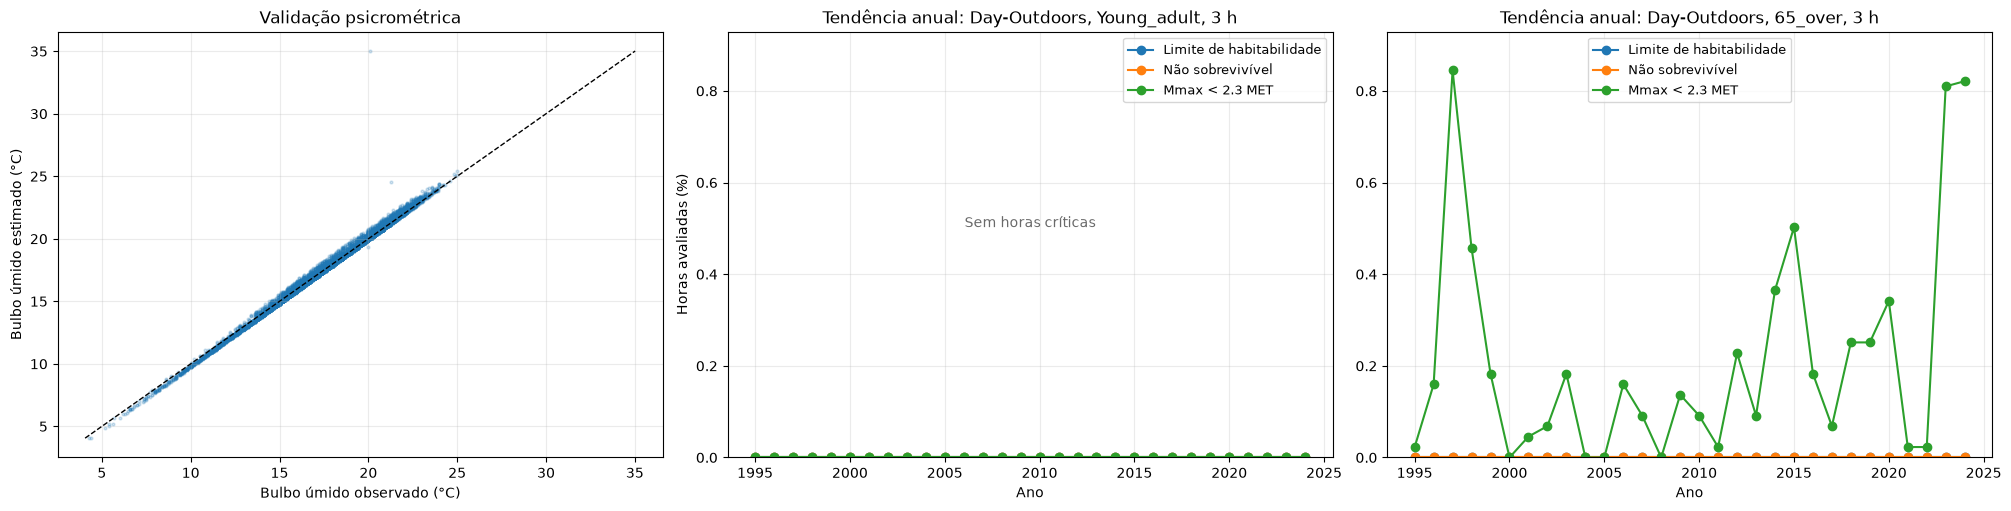

In [13]:
# Validação do bulbo úmido: uma amostra reduzida deixa o gráfico legível.
amostra_bulbo = observacoes_bulbo.sample(min(10000, len(observacoes_bulbo)), random_state=42)
figura, eixos = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)
eixos[0].scatter(
    amostra_bulbo["bulbo_umido_observado_C"],
    amostra_bulbo["bulbo_umido_estimado_C"],
    s=4, alpha=0.2, color="tab:blue",
)
limites = [
    min(amostra_bulbo["bulbo_umido_observado_C"].min(), amostra_bulbo["bulbo_umido_estimado_C"].min()),
    max(amostra_bulbo["bulbo_umido_observado_C"].max(), amostra_bulbo["bulbo_umido_estimado_C"].max()),
]
eixos[0].plot(limites, limites, "k--", linewidth=1)
eixos[0].set_xlabel("Bulbo úmido observado (°C)")
eixos[0].set_ylabel("Bulbo úmido estimado (°C)")
eixos[0].set_title("Validação psicrométrica")
eixos[0].grid(alpha=0.25)

rotulos = {
    "limite_sobrevivencia_ultrapassado": "Não sobrevivível",
    "limite_habitabilidade_ultrapassado": "Limite de habitabilidade",
    "mmax_abaixo_limiar": f"Mmax < {LIMIAR_ATIVIDADE_MET:.1f} MET",
}
for eixo, (exposicao, perfil, duracao) in zip(eixos[1:], CENARIOS_DESTAQUE):
    taxas_destaque = taxas_anuais.loc[
        (taxas_anuais["exposure"] == exposicao)
        & (taxas_anuais["profile_id"] == perfil)
        & (taxas_anuais["duration_h"] == duracao)
    ]
    for indicador, tabela in taxas_destaque.groupby("indicador"):
        eixo.plot(tabela["ano"], tabela["percentual"], "o-", label=rotulos[indicador])
    eixo.set_title(f"Tendência anual: {exposicao}, {perfil}, {duracao} h")
    eixo.set_xlabel("Ano")
    eixo.grid(alpha=0.25)
    eixo.legend(fontsize=9)
    if taxas_destaque["percentual"].eq(0).all():
        eixo.text(0.5, 0.55, "Sem horas críticas", transform=eixo.transAxes,
                  ha="center", va="center", color="dimgray")

eixos[1].set_ylabel("Horas avaliadas (%)")
limite_superior = max(
    taxas_anuais.loc[
        taxas_anuais[["exposure", "profile_id", "duration_h"]]
        .apply(tuple, axis=1).isin(CENARIOS_DESTAQUE), "percentual"
    ].max() * 1.1,
    0.1,
)
for eixo in eixos[1:]:
    eixo.set_ylim(0, limite_superior)
plt.show()

## Próximas análises recomendadas

- Estratificar os eventos sustentados identificados por mês e por década, para examinar sua sazonalidade e evolução temporal.
- Usar radiação solar, vento e condições internas medidas ou modeladas; eles podem alterar muito as estimativas de habitabilidade.
- Criar heatmaps de ano × mês e hora × mês das taxas de ultrapassagem.
- Comparar eventos de bulbo úmido acima do P95 com horas de `Mmax` abaixo de níveis específicos de atividade.
- Fazer análise de sensibilidade para roupas, aclimatação e velocidade do vento, reportando faixas de incerteza em vez de apenas um cenário.